In [31]:
%%capture
!pip install ucimlrepo

In [32]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

In [34]:
productivity_ds = fetch_ucirepo(id=597)

X = productivity_ds.data.features.drop(columns=["date"])
y = productivity_ds.data.targets



In [35]:
X.isna().sum()

,0
quarter,0
department,0
day,0
team,0
targeted_productivity,0
smv,0
wip,506
over_time,0
incentive,0
idle_time,0


In [36]:
y.isna().sum()

,0
actual_productivity,0


In [37]:
X.describe(include="number")

,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers
count,1197.000000,1197.000000,1197.000000,691.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,6.426901,0.729632,15.062172,1190.465991,4567.460317,38.210526,0.730159,0.369256,0.150376,34.609858
std,3.463963,0.097891,10.943219,1837.455001,3348.823563,160.182643,12.709757,3.268987,0.427848,22.197687
min,1.000000,0.070000,2.900000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
25%,3.000000,0.700000,3.940000,774.500000,1440.000000,0.000000,0.000000,0.000000,0.000000,9.000000
50%,6.000000,0.750000,15.260000,1039.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,34.000000
75%,9.000000,0.800000,24.260000,1252.500000,6960.000000,50.000000,0.000000,0.000000,0.000000,57.000000
max,12.000000,0.800000,54.560000,23122.000000,25920.000000,3600.000000,300.000000,45.000000,2.000000,89.000000


In [38]:
X.dtypes

,0
quarter,object
department,object
day,object
team,int64
targeted_productivity,float64
smv,float64
wip,float64
over_time,int64
incentive,int64
idle_time,float64


In [39]:
productivity_ds.variables

,name,role,type,demographic,description,units,missing_values
0,date,Feature,Date,None,None,None,no
1,quarter,Feature,Categorical,None,None,None,no
2,department,Feature,Categorical,None,None,None,no
3,day,Feature,Categorical,None,None,None,no
4,team,Feature,Integer,None,None,None,no
5,targeted_productivity,Feature,Continuous,None,None,None,no
6,smv,Feature,Continuous,None,None,None,no
7,wip,Feature,Integer,None,None,None,yes
8,over_time,Feature,Integer,None,None,None,no
9,incentive,Feature,Integer,None,None,BDT,no


In [40]:
cat_cols_names = X.select_dtypes("object").columns.to_list()
X[cat_cols_names] = X.loc[:, cat_cols_names].astype('category')

In [41]:
onehot = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
encoded_columns = onehot.fit_transform(X[cat_cols_names])

In [42]:
X = pd.concat([encoded_columns, X.drop(columns=cat_cols_names)], axis=1).copy()
X["wip"] = X["wip"].fillna(X["wip"].mean()).copy()
X.sample(5)

,quarter_Quarter1,quarter_Quarter2,quarter_Quarter3,quarter_Quarter4,quarter_Quarter5,department_finishing,department_sweing,day_Monday,day_Saturday,day_Sunday,...,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers
1081,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,5,0.70,27.48,230.000000,6960,40,0.0,0,0,58.0
524,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1,0.75,3.94,1190.465991,1800,0,0.0,0,0,15.0
678,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,2,0.80,22.52,1413.000000,360,70,0.0,0,0,57.0
1024,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,7,0.80,4.60,1190.465991,3360,0,0.0,0,0,8.0
1155,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1,0.75,3.94,1190.465991,960,0,0.0,0,0,8.0


In [43]:
def split_to_cls(x):
    if x <= 0.5:
        return 0
    elif 0.5 < x <= 0.8:
        return 1
    else:
        return 2

In [44]:
y_cls_target = y["actual_productivity"].apply(split_to_cls)

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

In [46]:
X_tarin, X_test, y_train, y_test = train_test_split(
    X,
    y_cls_target,
    test_size=0.2,
    stratify=y_cls_target
)

In [47]:
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=7,
    class_weight="balanced"
)

In [48]:
model.fit(X_tarin, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=7)

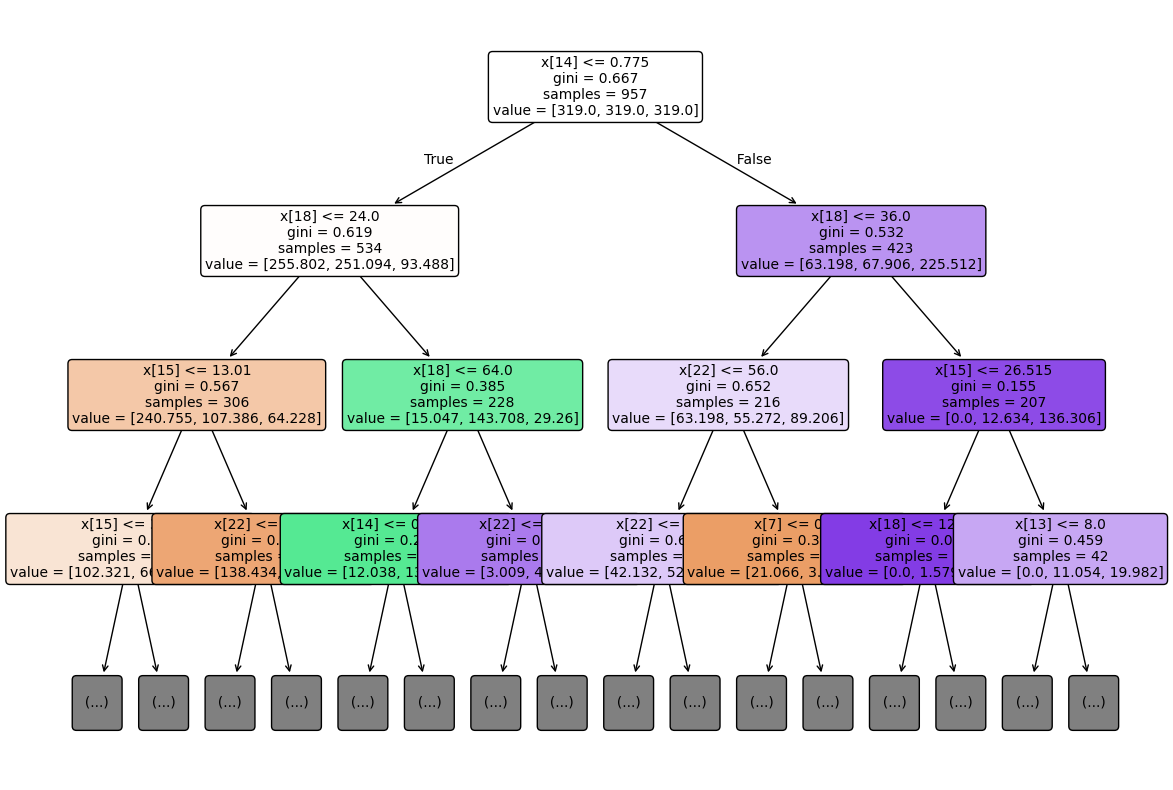

In [49]:
plt.figure(figsize=(12, 8))
plot_tree(
    decision_tree=model,
    max_depth = 3,
    rounded = True,
    filled = True,
    fontsize = 10
)
plt.tight_layout()
plt.show()

In [50]:
y_preds = model.predict(X_test)
print(classification_report(y_test, y_preds))

              precision    recall  f1-score   support

           0       0.32      0.56      0.41        27
           1       0.77      0.57      0.66       101
           2       0.76      0.80      0.78       112

    accuracy                           0.68       240
   macro avg       0.62      0.64      0.62       240
weighted avg       0.72      0.68      0.69       240



In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

In [52]:
cm = confusion_matrix(y_test, y_preds)
cm

array([[15,  7,  5],
       [20, 58, 23],
       [12, 10, 90]])

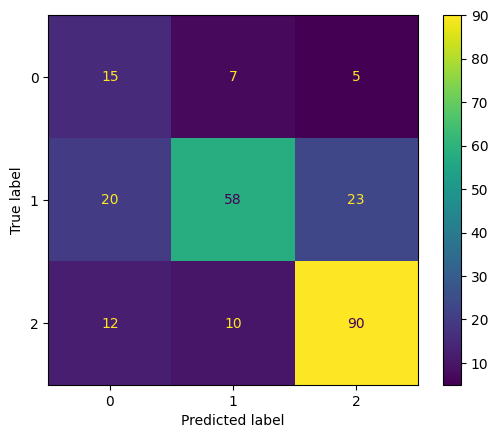

In [53]:
display = ConfusionMatrixDisplay(confusion_matrix=cm)
display.plot()
plt.show()

# pruning \ daraxtni kesish
# pre_pruning \ quriyotganda kesish
# post_pruning \ qurigandan keyin kesish

In [78]:
# pre-pruning
model2 = DecisionTreeClassifier(
    max_depth=20,
    # min_samples_split = 30,
    # min_samples_leaf = 40,
    # max_leaf_nodes = 10,
    # min_impurity_decrease = 0.005,
    ccp_alpha = 0.02365275,
    random_state=42
)

In [79]:
model2.fit(X_tarin, y_train)

DecisionTreeClassifier(ccp_alpha=0.02365275, max_depth=20, random_state=42)

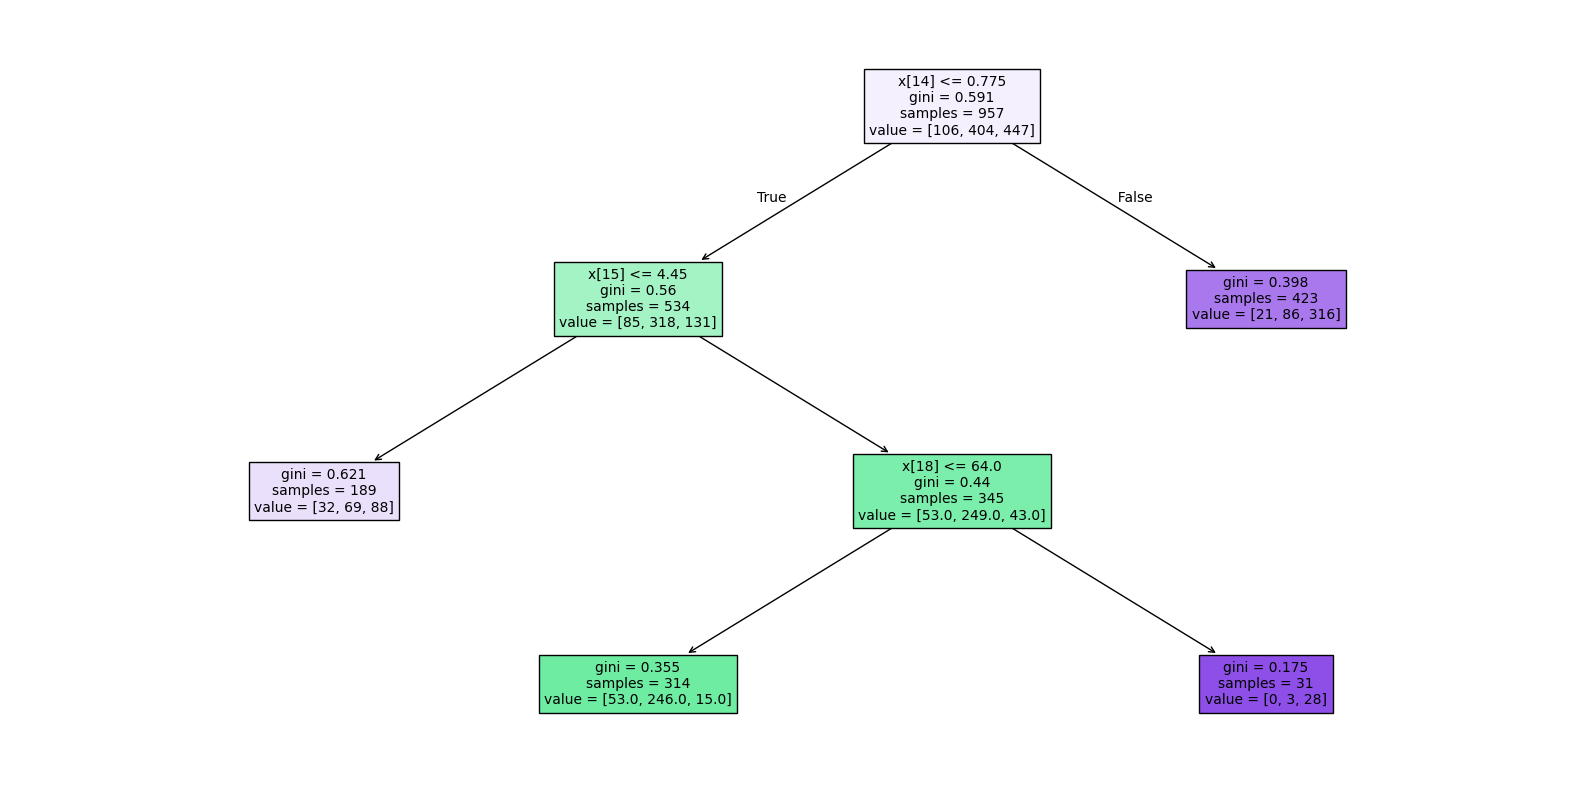

In [80]:
plt.figure(figsize=(16, 8))
plot_tree(
    decision_tree = model2,
    max_depth=5,
    filled=True,
    fontsize=10
)

plt.tight_layout()
plt.show()

In [81]:
model2.cost_complexity_pruning_path(X_tarin, y_train)

{'ccp_alphas': array([0.        , 0.00062696, 0.00069235, 0.00069662, 0.00069662,
        0.00069662, 0.00069662, 0.00069662, 0.00069662, 0.00071055,
        0.0007837 , 0.0007837 , 0.0007837 , 0.0007837 , 0.0007837 ,
        0.00083595, 0.00083595, 0.00083595, 0.00083595, 0.00083595,
        0.00087078, 0.00087078, 0.00088661, 0.00089566, 0.00089644,
        0.00091432, 0.00094044, 0.00094697, 0.00096134, 0.00097029,
        0.00099269, 0.00099517, 0.00100761, 0.0010101 , 0.0010295 ,
        0.00104493, 0.00104493, 0.00104493, 0.00104493, 0.00107479,
        0.00111459, 0.00111957, 0.00119421, 0.0012278 , 0.00125392,
        0.00125392, 0.00129373, 0.00132358, 0.00134588, 0.00135047,
        0.00139324, 0.00139324, 0.00139324, 0.00139324, 0.00139324,
        0.00139324, 0.00139324, 0.00139324, 0.00139324, 0.00139324,
        0.00143305, 0.0014629 , 0.00154907, 0.0015674 , 0.00159228,
        0.00159228, 0.00160223, 0.00161932, 0.00162118, 0.00165199,
        0.00173984, 0.00174155, 0.